### Pillow 2: Zeichnen - Übungen

Mit `ImageDraw` zeichnest du Linien, Rechtecke, Kreise, Vielecke und Text in ein Bild. Zusammen mit Schleifen und Funktionen entstehen daraus Flaggen,
Muster, Uhren und Diagramme. (Die Turtle-Grafik, die du vielleicht kennst, gibt es im Browser-Python nicht; Pillow ist ein guter Ersatz.)

Die Reihe hat vier Notebooks:

1. Grundlagen: Bilder erzeugen, Pixel, Farben, Speichern und Öffnen
2. **Zeichnen**: Formen, Text, Grafiken mit Schleifen und Funktionen (dieses Notebook)
3. Bearbeiten: Ausschneiden, Drehen, Filter, Helligkeit, Collagen, animierte GIFs
4. Pixel: Bildverarbeitung selbst programmieren, mit Schleifen und mit numpy

Vorausgesetzt werden *Pillow: Grundlagen* und die Notebooks *Schleifen* und *Funktionen*.

**Bilder anzeigen:** Steht ein Bild in der **letzten Zeile** einer Zelle, zeigt JupyterLab es an. Mehrere Bilder in einer Zelle zeigt man mit `display(bild)` an.
Die erwarteten Ausgaben zeigen die Bilder höchstens 320 Pixel groß; große Bilder (Fotos) sind dort verkleinert.

Jeder Abschnitt beginnt mit kurzen Erklärungen und Beispielen. Führe die Beispiele aus und probiere sie ruhig ein wenig aus.
Danach folgen viele kleine Übungen. Wenn etwas vorgegeben ist, steht es schon in der Codezelle.

Unter den Aufgaben kannst du jeweils die Lösung aufklappen. Versuche es aber immer zuerst selbst!
Bei den Aufgaben „Was wird ausgegeben?“ überlegst du zuerst, führst dann die Zelle aus und vergleichst.
Die aufklappbare Lösung erklärt dort, wie die Ausgabe zustande kommt.

#### Bildanzeige einrichten

**Führe diese Zelle zuerst aus** (nach jedem Neustart des Kernels wieder). Im Browser-Python von JupyterLite zeigt `display(bild)` sonst nur ein leeres Bild an;
die Zelle sorgt dafür, dass Pillow-Bilder dort richtig übertragen werden. Wie sie funktioniert, musst du nicht verstehen.

In [ ]:
import base64
import io
from IPython import get_ipython
from PIL import Image

def als_png(bild):
    puffer = io.BytesIO()
    bild.save(puffer, 'PNG')
    return base64.b64encode(puffer.getvalue()).decode('ascii')

def kein_jpeg(bild):
    return None

ipython = get_ipython()
if ipython is not None:
    ipython.display_formatter.formatters['image/png'].for_type(Image.Image, als_png)
    ipython.display_formatter.formatters['image/jpeg'].for_type(Image.Image, kein_jpeg)
print('Bereit: Bilder werden auch mit display() angezeigt.')

## 1. Linien, Rechtecke und Ellipsen

#### `ImageDraw.Draw()`

`zeichner = ImageDraw.Draw(bild)` erzeugt einen **Zeichner** für ein Bild. Alles, was er zeichnet, landet direkt in `bild`.

| Aufruf | zeichnet |
|---|---|
| `zeichner.line((x1, y1, x2, y2), fill=farbe, width=3)` | eine Strecke (`width`: Strichstärke) |
| `zeichner.rectangle((x1, y1, x2, y2), fill=..., outline=..., width=...)` | ein Rechteck mit den Ecken oben links und unten rechts |
| `zeichner.ellipse((x1, y1, x2, y2), fill=..., outline=...)` | eine Ellipse, die in dieses Rechteck passt (ein Kreis, wenn es ein Quadrat ist) |

`fill` ist die Füllfarbe, `outline` die Farbe des Rands. Wie bei den Pixeln ist `(0, 0)` oben links und `y` wächst nach unten.

In [ ]:
from PIL import Image, ImageDraw

bild = Image.new('RGB', (300, 200), 'white')
zeichner = ImageDraw.Draw(bild)
zeichner.line((10, 190, 290, 10), fill='gray', width=3)
zeichner.rectangle((20, 20, 120, 100), fill='gold', outline='black', width=2)
zeichner.ellipse((150, 50, 250, 150), fill='skyblue', outline='navy', width=4)
bild

#### Kreise mit Mittelpunkt und Radius

Für einen Kreis mit Mittelpunkt `(mx, my)` und Radius `r` ist das umgebende Quadrat `(mx - r, my - r, mx + r, my + r)`.
`zeichner.circle((mx, my), r, fill=...)` macht dasselbe direkt.
Mehrere Strecken hintereinander zeichnet `zeichner.line([(x1, y1), (x2, y2), (x3, y3)], ...)` mit einer **Liste** von Punkten.

In [ ]:
from PIL import Image, ImageDraw

bild = Image.new('RGB', (300, 200), 'white')
zeichner = ImageDraw.Draw(bild)
mx, my, r = 80, 100, 50
zeichner.ellipse((mx - r, my - r, mx + r, my + r), fill='tomato')
zeichner.circle((220, 100), 50, fill='limegreen')
zeichner.line([(10, 10), (150, 60), (290, 10)], fill='black', width=2)
bild

#### Aufgabe 1.1

Zeichne in das weiße Bild ein rotes Rechteck von (50 | 40) bis (250 | 160) mit einem schwarzen Rand der Breite 3.

**Erwartete Ausgabe:**



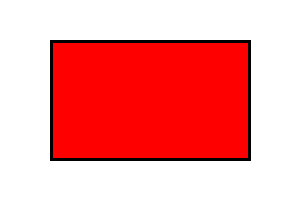

In [ ]:
from PIL import Image, ImageDraw

bild = Image.new('RGB', (300, 200), 'white')
zeichner = ImageDraw.Draw(bild)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image, ImageDraw

bild = Image.new('RGB', (300, 200), 'white')
zeichner = ImageDraw.Draw(bild)
zeichner.rectangle((50, 40, 250, 160), fill='red', outline='black', width=3)
bild
```

</details>

#### Aufgabe 1.2

Zeichne die beiden Diagonalen des Bilds als blaue Linien der Breite 4.

**Erwartete Ausgabe:**



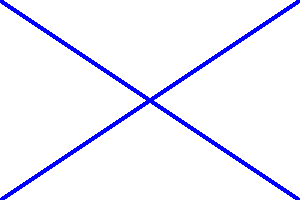

In [ ]:
from PIL import Image, ImageDraw

bild = Image.new('RGB', (300, 200), 'white')
zeichner = ImageDraw.Draw(bild)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image, ImageDraw

bild = Image.new('RGB', (300, 200), 'white')
zeichner = ImageDraw.Draw(bild)
zeichner.line((0, 0, 299, 199), fill='blue', width=4)
zeichner.line((0, 199, 299, 0), fill='blue', width=4)
bild
```

</details>

#### Aufgabe 1.3

Zeichne einen gelben Kreis mit dem Mittelpunkt (150 | 100) und dem Radius 80 mit orangem Rand (Breite 5), einmal mit `ellipse()`.

**Erwartete Ausgabe:**



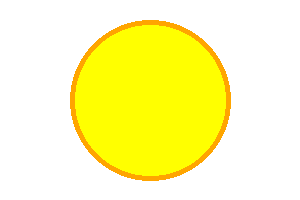

In [ ]:
from PIL import Image, ImageDraw

bild = Image.new('RGB', (300, 200), 'white')
zeichner = ImageDraw.Draw(bild)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image, ImageDraw

bild = Image.new('RGB', (300, 200), 'white')
zeichner = ImageDraw.Draw(bild)
mx, my, r = 150, 100, 80
zeichner.ellipse((mx - r, my - r, mx + r, my + r), fill='yellow', outline='orange', width=5)
bild
```

</details>

#### Aufgabe 1.4

Zeichne ein **Haus**: ein braunes Rechteck (60 | 90) bis (240 | 190) als Wand, ein rotes Dreieck als Dach mit einer geschlossenen Linie durch die Punkte
(50 | 90), (150 | 20), (250 | 90), (50 | 90) (Breite 4) und eine dunkelbraune Tür (130 | 130) bis (170 | 190).

**Erwartete Ausgabe:**



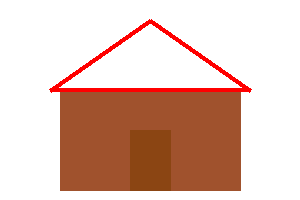

In [ ]:
from PIL import Image, ImageDraw

bild = Image.new('RGB', (300, 200), 'white')
zeichner = ImageDraw.Draw(bild)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image, ImageDraw

bild = Image.new('RGB', (300, 200), 'white')
zeichner = ImageDraw.Draw(bild)
zeichner.rectangle((60, 90, 240, 190), fill='sienna')
zeichner.line([(50, 90), (150, 20), (250, 90), (50, 90)], fill='red', width=4)
zeichner.rectangle((130, 130, 170, 190), fill='saddlebrown')
bild
```

</details>

#### Aufgabe 1.5

Zeichne die Olympischen Ringe: fünf Kreise mit Radius 40 und Randbreite 6, ohne Füllung, oben mit den Mittelpunkten (60 | 70), (150 | 70), (240 | 70) in Blau, Schwarz, Rot,
unten (105 | 120), (195 | 120) in Gelb und Grün. Benutze eine Schleife über eine Liste von (Mittelpunkt, Farbe).

**Erwartete Ausgabe:**



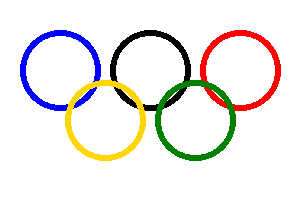

In [ ]:
from PIL import Image, ImageDraw

bild = Image.new('RGB', (300, 200), 'white')
zeichner = ImageDraw.Draw(bild)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image, ImageDraw

bild = Image.new('RGB', (300, 200), 'white')
zeichner = ImageDraw.Draw(bild)
ringe = [((60, 70), 'blue'), ((150, 70), 'black'), ((240, 70), 'red'), ((105, 120), 'gold'), ((195, 120), 'green')]
for (mx, my), farbe in ringe:
    zeichner.circle((mx, my), 40, outline=farbe, width=6)
bild
```

</details>

#### Aufgabe 1.6

Zeichne ein Gitter: senkrechte graue Linien bei `x` = 0, 20, 40, ..., 280 und waagerechte bei `y` = 0, 20, ..., 180.

**Erwartete Ausgabe:**



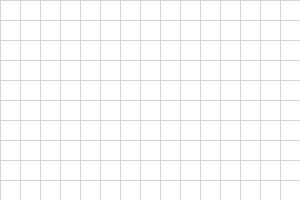

In [ ]:
from PIL import Image, ImageDraw

bild = Image.new('RGB', (300, 200), 'white')
zeichner = ImageDraw.Draw(bild)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image, ImageDraw

bild = Image.new('RGB', (300, 200), 'white')
zeichner = ImageDraw.Draw(bild)
for x in range(0, 300, 20):
    zeichner.line((x, 0, x, 199), fill='lightgray')
for y in range(0, 200, 20):
    zeichner.line((0, y, 299, y), fill='lightgray')
bild
```

</details>

#### Aufgabe 1.7

Zeichne die Flagge von Schweden (300 × 190): blauer Hintergrund `'#006aa7'`, darauf ein gelbes Kreuz `'#fecc00'` aus zwei Rechtecken:
waagerecht (0 | 76) bis (299 | 113) und senkrecht (95 | 0) bis (132 | 189).

**Erwartete Ausgabe:**



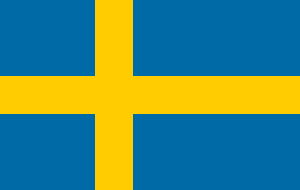

In [ ]:
from PIL import Image, ImageDraw
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image, ImageDraw
bild = Image.new('RGB', (300, 190), '#006aa7')
zeichner = ImageDraw.Draw(bild)
zeichner.rectangle((0, 76, 299, 113), fill='#fecc00')
zeichner.rectangle((95, 0, 132, 189), fill='#fecc00')
bild
```

</details>

#### Aufgabe 1.8

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
from PIL import Image, ImageDraw

bild = Image.new('RGB', (10, 10), 'white')
zeichner = ImageDraw.Draw(bild)
zeichner.rectangle((2, 2, 5, 5), fill='black')
print(bild.getpixel((2, 2)), bild.getpixel((5, 5)), bild.getpixel((6, 6)))

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

**Ausgabe:**

```
(0, 0, 0) (0, 0, 0) (255, 255, 255)
```

Das Rechteck reicht von (2 | 2) bis **einschließlich** (5 | 5). Beide Ecken sind schwarz: `(0, 0, 0) (0, 0, 0)`.
Das Pixel (6 | 6) liegt außerhalb und bleibt weiß: `(255, 255, 255)`.

</details>

## 2. Vielecke, Bögen und Tortenstücke

#### `polygon()`, `arc()` und `pieslice()`

- `zeichner.polygon([(x1, y1), (x2, y2), ...], fill=..., outline=...)`: ein Vieleck durch die Punkte (das letzte wird mit dem ersten verbunden).
- `zeichner.arc(rechteck, start, ende, fill=..., width=...)`: ein Bogen der Ellipse in `rechteck` von Winkel `start` bis `ende`.
- `zeichner.pieslice(rechteck, start, ende, fill=...)`: ein Tortenstück.
- `zeichner.rounded_rectangle(rechteck, radius=15, fill=...)`: ein Rechteck mit abgerundeten Ecken.

Die Winkel sind in Grad. **Achtung:** 0° zeigt nach rechts, und die Winkel wachsen **im Uhrzeigersinn** (weil `y` nach unten wächst), 90° zeigt also nach unten.

In [ ]:
from PIL import Image, ImageDraw

bild = Image.new('RGB', (300, 200), 'white')
zeichner = ImageDraw.Draw(bild)
zeichner.polygon([(20, 180), (80, 20), (140, 180)], fill='orange', outline='black')
zeichner.pieslice((160, 40, 280, 160), 30, 330, fill='gold')
zeichner.arc((160, 40, 280, 160), 0, 90, fill='red', width=5)
zeichner.rounded_rectangle((20, 10, 60, 40), radius=10, fill='plum')
bild

#### Aufgabe 2.1

Zeichne ein grünes Dreieck mit den Ecken (150 | 20), (270 | 180), (30 | 180) und schwarzem Rand.

**Erwartete Ausgabe:**



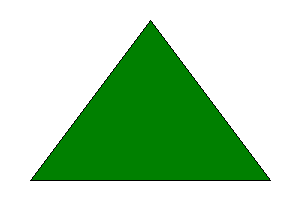

In [ ]:
from PIL import Image, ImageDraw

bild = Image.new('RGB', (300, 200), 'white')
zeichner = ImageDraw.Draw(bild)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image, ImageDraw

bild = Image.new('RGB', (300, 200), 'white')
zeichner = ImageDraw.Draw(bild)
zeichner.polygon([(150, 20), (270, 180), (30, 180)], fill='green', outline='black')
bild
```

</details>

#### Aufgabe 2.2

Zeichne ein Stoppschild-Achteck: Die Ecken liegen auf einem Kreis um (150 | 100) mit Radius 90, bei den Winkeln 22.5°, 67.5°, 112.5°, ... (Schritte von 45°).
Eine Ecke hat die Koordinaten `(150 + 90 · cos(w), 100 + 90 · sin(w))` (Winkel im Bogenmaß: `math.radians()`). Fülle es rot.

**Erwartete Ausgabe:**



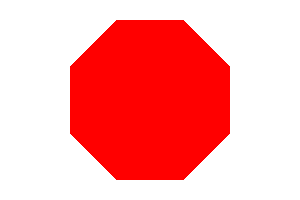

In [ ]:
from PIL import Image, ImageDraw

bild = Image.new('RGB', (300, 200), 'white')
zeichner = ImageDraw.Draw(bild)
import math
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image, ImageDraw

bild = Image.new('RGB', (300, 200), 'white')
zeichner = ImageDraw.Draw(bild)
import math
ecken = []
for i in range(8):
    w = math.radians(22.5 + 45 * i)
    ecken.append((150 + 90 * math.cos(w), 100 + 90 * math.sin(w)))
zeichner.polygon(ecken, fill='red', outline='white', width=4)
bild
```

</details>

#### Aufgabe 2.3

Schreibe eine Funktion `vieleck(zeichner, mx, my, r, n, farbe)`, die ein regelmäßiges `n`-Eck mit Mittelpunkt (mx | my) und Umkreisradius `r` zeichnet (erste Ecke bei −90°,
also oben). Zeichne damit in ein 400 × 120-Bild ein Dreieck, Viereck, Fünfeck und Sechseck nebeneinander (Mittelpunkte bei x = 60, 160, 260, 360, y = 60, r = 45).

**Erwartete Ausgabe:**



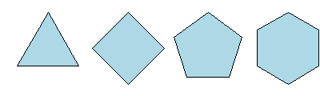

In [ ]:
from PIL import Image, ImageDraw
import math
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image, ImageDraw
import math

def vieleck(zeichner, mx, my, r, n, farbe):
    ecken = []
    for i in range(n):
        w = math.radians(-90 + 360 / n * i)
        ecken.append((mx + r * math.cos(w), my + r * math.sin(w)))
    zeichner.polygon(ecken, fill=farbe, outline='black')

bild = Image.new('RGB', (400, 120), 'white')
zeichner = ImageDraw.Draw(bild)
for nr, n in enumerate([3, 4, 5, 6]):
    vieleck(zeichner, 60 + 100 * nr, 60, 45, n, 'lightblue')
bild
```

</details>

#### Aufgabe 2.4

Zeichne einen fünfzackigen **Stern**: Die 10 Ecken liegen abwechselnd auf einem Kreis mit Radius 90 und einem mit Radius 36 um (150 | 100), bei den Winkeln
−90°, −54°, −18°, ... (Schritte von 36°). Fülle ihn gelb.

**Erwartete Ausgabe:**



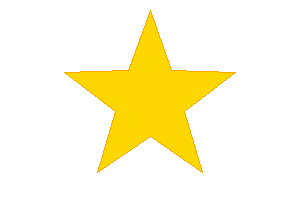

In [ ]:
from PIL import Image, ImageDraw

bild = Image.new('RGB', (300, 200), 'white')
zeichner = ImageDraw.Draw(bild)
import math
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image, ImageDraw

bild = Image.new('RGB', (300, 200), 'white')
zeichner = ImageDraw.Draw(bild)
import math
ecken = []
for i in range(10):
    if i % 2 == 0:
        r = 90
    else:
        r = 36
    w = math.radians(-90 + 36 * i)
    ecken.append((150 + r * math.cos(w), 100 + r * math.sin(w)))
zeichner.polygon(ecken, fill='gold', outline='orange')
bild
```

</details>

#### Aufgabe 2.5

Zeichne einen **Smiley**: gelbes Gesicht (Kreis um (150 | 100), Radius 80), zwei schwarze Augen (Radius 10, bei (120 | 75) und (180 | 75)) und einen Mund als Bogen
der Ellipse (100 | 70) bis (200 | 150) von 20° bis 160°, Breite 5.

**Erwartete Ausgabe:**



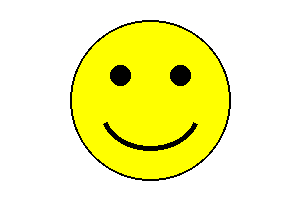

In [ ]:
from PIL import Image, ImageDraw

bild = Image.new('RGB', (300, 200), 'white')
zeichner = ImageDraw.Draw(bild)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image, ImageDraw

bild = Image.new('RGB', (300, 200), 'white')
zeichner = ImageDraw.Draw(bild)
zeichner.circle((150, 100), 80, fill='yellow', outline='black', width=2)
zeichner.circle((120, 75), 10, fill='black')
zeichner.circle((180, 75), 10, fill='black')
zeichner.arc((100, 70, 200, 150), 20, 160, fill='black', width=5)
bild
```

</details>

#### Aufgabe 2.6

Zeichne mit `pieslice()` eine Pac-Man-Figur: ein gelber Kreis um (150 | 100) mit Radius 80, dem rechts ein Stück von 60° fehlt (von 30° bis 330° zeichnen),
und ein schwarzes Auge (Radius 8) bei (160 | 55).

**Erwartete Ausgabe:**



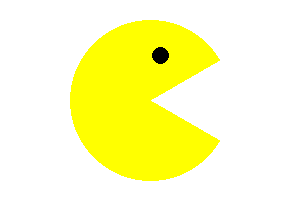

In [ ]:
from PIL import Image, ImageDraw

bild = Image.new('RGB', (300, 200), 'white')
zeichner = ImageDraw.Draw(bild)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image, ImageDraw

bild = Image.new('RGB', (300, 200), 'white')
zeichner = ImageDraw.Draw(bild)
zeichner.pieslice((70, 20, 230, 180), 30, 330, fill='yellow')
zeichner.circle((160, 55), 8, fill='black')
bild
```

</details>

#### Aufgabe 2.7

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
import math

for i in range(4):
    w = math.radians(90 * i)
    print(round(100 + 50 * math.cos(w)), round(100 + 50 * math.sin(w)))

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

**Ausgabe:**

```
150 100
100 150
50 100
100 50
```

Die Punkte liegen auf einem Kreis um (100 | 100) mit Radius 50, bei 0°, 90°, 180°, 270°. Weil `y` nach unten wächst:
0° rechts `150 100`, 90° **unten** `100 150`, 180° links `50 100`, 270° oben `100 50`.

</details>

## 3. Text

#### `zeichner.text()`

`zeichner.text((x, y), 'Hallo', fill=farbe, font=schrift)` schreibt Text. Die Schrift erzeugt `ImageFont.load_default(size=40)`: die eingebaute Schrift von Pillow
in der Größe 40 Pixel. Mit `anchor` legt man fest, welcher Punkt des Texts bei `(x, y)` liegt: Standard ist oben links (`'la'`), `'mm'` bedeutet die **Mitte** (waagerecht
und senkrecht). So lässt sich Text leicht zentrieren.

In [ ]:
from PIL import Image, ImageDraw, ImageFont

bild = Image.new('RGB', (300, 120), 'white')
zeichner = ImageDraw.Draw(bild)
klein = ImageFont.load_default(size=16)
gross = ImageFont.load_default(size=40)
zeichner.text((5, 5), 'oben links', fill='gray', font=klein)
zeichner.text((150, 65), 'Hallo!', fill='navy', font=gross, anchor='mm')
zeichner.line((150, 0, 150, 119), fill='lightgray')
bild

#### Umlaute: eine andere Schrift

Die eingebaute Schrift von Pillow kennt **keine Umlaute** (ä, ö, ü, ß): Statt ihrer erscheinen Kästchen. Eine Schrift mit Umlauten bringt das Paket matplotlib mit,
*DejaVu Sans*. `ImageFont.truetype(pfad, 30)` lädt eine Schriftdatei in der Größe 30. Den Ordner von matplotlib liefert `matplotlib.get_data_path()`;
es gibt dort auch `DejaVuSans-Bold.ttf` (fett) und `DejaVuSerif.ttf` (mit Serifen).

In [ ]:
from PIL import Image, ImageDraw, ImageFont
import matplotlib

pfad = matplotlib.get_data_path() + '/fonts/ttf/DejaVuSans.ttf'
bild = Image.new('RGB', (300, 100), 'white')
zeichner = ImageDraw.Draw(bild)
zeichner.text((150, 30), 'Größe: süß', fill='black', font=ImageFont.load_default(size=28), anchor='mm')
zeichner.text((150, 70), 'Größe: süß', fill='black', font=ImageFont.truetype(pfad, 28), anchor='mm')
bild

#### Aufgabe 3.1

Schreibe „Grüße aus Köln“ in Größe 32 mittig in ein hellgelbes 360 × 80-Bild, mit der fetten Schrift `DejaVuSans-Bold.ttf` aus matplotlib.

**Erwartete Ausgabe:**



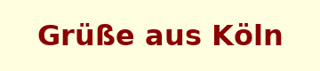

In [ ]:
from PIL import Image, ImageDraw, ImageFont
import matplotlib
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image, ImageDraw, ImageFont
import matplotlib
pfad = matplotlib.get_data_path() + '/fonts/ttf/DejaVuSans-Bold.ttf'
bild = Image.new('RGB', (360, 80), 'lightyellow')
ImageDraw.Draw(bild).text((180, 40), 'Grüße aus Köln', fill='darkred', font=ImageFont.truetype(pfad, 32), anchor='mm')
bild
```

</details>

#### Aufgabe 3.2

Schreibe deinen Namen (hier: `Mia`) in der Größe 60 in Rot mittig in ein weißes 300 × 150-Bild.

**Erwartete Ausgabe:**



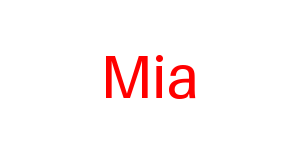

In [ ]:
from PIL import Image, ImageDraw, ImageFont
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image, ImageDraw, ImageFont
bild = Image.new('RGB', (300, 150), 'white')
zeichner = ImageDraw.Draw(bild)
zeichner.text((150, 75), 'Mia', fill='red', font=ImageFont.load_default(size=60), anchor='mm')
bild
```

</details>

#### Aufgabe 3.3

Erzeuge ein Namensschild: ein abgerundetes Rechteck (10 | 10) bis (290 | 110) mit Radius 20, hellblau mit dunkelblauem Rand (Breite 3), darin oben mittig in Größe 18
„Hallo, ich bin“ und darunter mittig in Größe 36 „Mia“.

**Erwartete Ausgabe:**



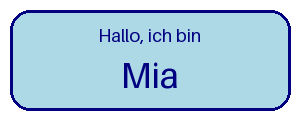

In [ ]:
from PIL import Image, ImageDraw, ImageFont
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image, ImageDraw, ImageFont
bild = Image.new('RGB', (300, 120), 'white')
zeichner = ImageDraw.Draw(bild)
zeichner.rounded_rectangle((10, 10, 290, 110), radius=20, fill='lightblue', outline='navy', width=3)
zeichner.text((150, 35), 'Hallo, ich bin', fill='navy', font=ImageFont.load_default(size=18), anchor='mm')
zeichner.text((150, 75), 'Mia', fill='navy', font=ImageFont.load_default(size=36), anchor='mm')
bild
```

</details>

#### Aufgabe 3.4

Schreibe die Zahlen 1 bis 9 als 3 × 3-Gitter in ein 180 × 180-Bild: jede Zahl in Größe 30, mittig in einem 60 × 60-Feld mit grauem Rand.

**Erwartete Ausgabe:**



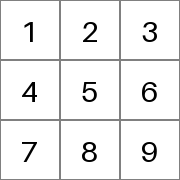

In [ ]:
from PIL import Image, ImageDraw, ImageFont
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image, ImageDraw, ImageFont
bild = Image.new('RGB', (180, 180), 'white')
zeichner = ImageDraw.Draw(bild)
schrift = ImageFont.load_default(size=30)
for i in range(9):
    x = i % 3 * 60
    y = i // 3 * 60
    zeichner.rectangle((x, y, x + 59, y + 59), outline='gray')
    zeichner.text((x + 30, y + 30), str(i + 1), fill='black', font=schrift, anchor='mm')
bild
```

</details>

#### Aufgabe 3.5

Ein Verkehrsschild: ein roter Kreis (Radius 90) um (100 | 100) mit einem weißen Kreis (Radius 70) darin und der Zahl „30“ in Schwarz, Größe 70, in der Mitte.

**Erwartete Ausgabe:**



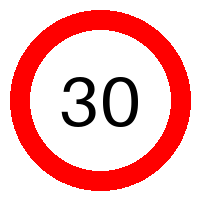

In [ ]:
from PIL import Image, ImageDraw, ImageFont
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image, ImageDraw, ImageFont
bild = Image.new('RGB', (200, 200), 'white')
zeichner = ImageDraw.Draw(bild)
zeichner.circle((100, 100), 90, fill='red')
zeichner.circle((100, 100), 70, fill='white')
zeichner.text((100, 100), '30', fill='black', font=ImageFont.load_default(size=70), anchor='mm')
bild
```

</details>

#### Aufgabe 3.6

Schreibe den Text „Pillow“ fünfmal untereinander in den Größen 12, 18, 24, 30 und 36 (linksbündig bei x = 10; die y-Koordinate wächst jeweils um die Größe plus 6).

**Erwartete Ausgabe:**



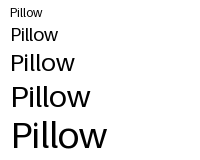

In [ ]:
from PIL import Image, ImageDraw, ImageFont
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image, ImageDraw, ImageFont
bild = Image.new('RGB', (200, 160), 'white')
zeichner = ImageDraw.Draw(bild)
y = 5
for groesse in [12, 18, 24, 30, 36]:
    zeichner.text((10, y), 'Pillow', fill='black', font=ImageFont.load_default(size=groesse))
    y += groesse + 6
bild
```

</details>

## 4. Muster mit Schleifen und Funktionen

#### Wiederholen und verschachteln

Zeichenbefehle in Schleifen erzeugen Muster mit wenig Code. Mit Funktionen, die einen Zeichner und eine Position bekommen, kann man eine Figur
an viele Stellen setzen.

In [ ]:
from PIL import Image, ImageDraw

def baum(zeichner, x, y):
    zeichner.rectangle((x - 4, y - 20, x + 4, y), fill='saddlebrown')
    zeichner.polygon([(x - 20, y - 15), (x, y - 60), (x + 20, y - 15)], fill='forestgreen')


bild = Image.new('RGB', (300, 120), 'lightcyan')
zeichner = ImageDraw.Draw(bild)
for x in range(30, 300, 60):
    baum(zeichner, x, 110)
bild

#### Aufgabe 4.1

Zeichne eine **Zielscheibe**: 10 Kreise um (150 | 150) mit den Radien 140, 126, 112, ..., 14 (vom größten zum kleinsten), abwechselnd rot und weiß.

**Erwartete Ausgabe:**



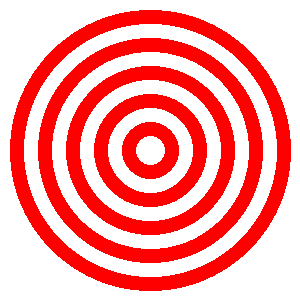

In [ ]:
from PIL import Image, ImageDraw
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image, ImageDraw
bild = Image.new('RGB', (300, 300), 'white')
zeichner = ImageDraw.Draw(bild)
for i in range(10):
    if i % 2 == 0:
        farbe = 'red'
    else:
        farbe = 'white'
    zeichner.circle((150, 150), 140 - 14 * i, fill=farbe)
bild
```

</details>

#### Aufgabe 4.2

Zeichne ein Schachbrett 8 × 8 mit Feldern von 30 × 30 Pixeln mit `rectangle()` (schwarz, wenn Zeile + Spalte gerade ist).

**Erwartete Ausgabe:**



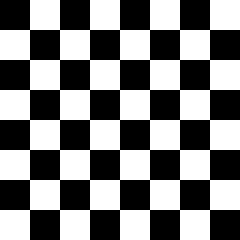

In [ ]:
from PIL import Image, ImageDraw
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image, ImageDraw
bild = Image.new('RGB', (240, 240), 'white')
zeichner = ImageDraw.Draw(bild)
for zeile in range(8):
    for spalte in range(8):
        if (zeile + spalte) % 2 == 0:
            zeichner.rectangle((spalte * 30, zeile * 30, spalte * 30 + 29, zeile * 30 + 29), fill='black')
bild
```

</details>

#### Aufgabe 4.3

Zeichne 36 Strahlen von der Mitte (150 | 150) eines 300 × 300-Bilds aus, alle 10°, jeweils 140 Pixel lang. Die Farbe ist `(i * 7, 0, 255 - i * 7)` für den Strahl `i`.

**Erwartete Ausgabe:**



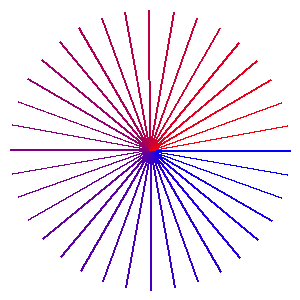

In [ ]:
from PIL import Image, ImageDraw
import math
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image, ImageDraw
import math
bild = Image.new('RGB', (300, 300), 'white')
zeichner = ImageDraw.Draw(bild)
for i in range(36):
    w = math.radians(10 * i)
    zeichner.line((150, 150, 150 + 140 * math.cos(w), 150 + 140 * math.sin(w)), fill=(i * 7, 0, 255 - i * 7), width=2)
bild
```

</details>

#### Aufgabe 4.4

Zeichne eine **Spirale** als Linie durch 300 Punkte: Für `i` von 0 bis 299 ist der Winkel `w = i · 0.1` (Bogenmaß) und der Abstand `r = i · 0.45` von der Mitte (150 | 150).

**Erwartete Ausgabe:**



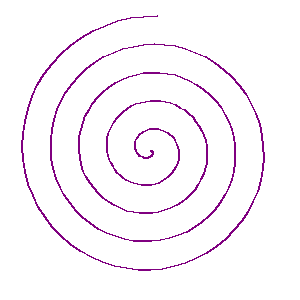

In [ ]:
from PIL import Image, ImageDraw
import math
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image, ImageDraw
import math
bild = Image.new('RGB', (300, 300), 'white')
zeichner = ImageDraw.Draw(bild)
punkte = []
for i in range(300):
    w = i * 0.1
    r = i * 0.45
    punkte.append((150 + r * math.cos(w), 150 + r * math.sin(w)))
zeichner.line(punkte, fill='purple', width=2)
bild
```

</details>

#### Aufgabe 4.5

Schreibe eine Funktion `blume(zeichner, x, y, farbe)`, die 6 Blütenblätter (Kreise mit Radius 12 im Abstand 15 um (x | y), alle 60°) in `farbe` und einen gelben Kreis
(Radius 9) in die Mitte zeichnet. Zeichne damit 5 Blumen in verschiedenen Farben nebeneinander (x = 40, 100, 160, 220, 280; y = 50) auf grünen Hintergrund.

**Erwartete Ausgabe:**



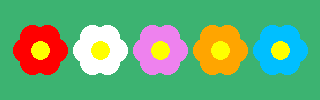

In [ ]:
from PIL import Image, ImageDraw
import math
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image, ImageDraw
import math

def blume(zeichner, x, y, farbe):
    for i in range(6):
        w = math.radians(60 * i)
        zeichner.circle((x + 15 * math.cos(w), y + 15 * math.sin(w)), 12, fill=farbe)
    zeichner.circle((x, y), 9, fill='yellow')

bild = Image.new('RGB', (320, 100), 'mediumseagreen')
zeichner = ImageDraw.Draw(bild)
for x, farbe in zip([40, 100, 160, 220, 280], ['red', 'white', 'violet', 'orange', 'deepskyblue']):
    blume(zeichner, x, 50, farbe)
bild
```

</details>

#### Aufgabe 4.6

Ein Sternenhimmel: Zeichne auf einen dunkelblauen Hintergrund (400 × 200) 150 weiße Punkte (Kreise mit Radius 1 oder 2, zufällig) an zufälligen Stellen (`random.seed(3)`)
und einen gelben Mond (Kreis um (330 | 50), Radius 30), von dem ein dunkelblauer Kreis um (345 | 45) mit Radius 28 einen Teil verdeckt.

**Erwartete Ausgabe:**



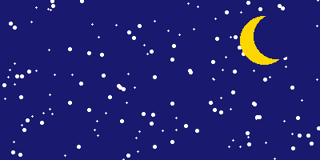

In [ ]:
from PIL import Image, ImageDraw
import random
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image, ImageDraw
import random
random.seed(3)
bild = Image.new('RGB', (400, 200), 'midnightblue')
zeichner = ImageDraw.Draw(bild)
for i in range(150):
    zeichner.circle((random.randint(0, 399), random.randint(0, 199)), random.randint(1, 2), fill='white')
zeichner.circle((330, 50), 30, fill='gold')
zeichner.circle((345, 45), 28, fill='midnightblue')
bild
```

</details>

#### Aufgabe 4.7

Zeichne 12 ineinander liegende Quadrate um die Mitte eines 300 × 300-Bilds (halbe Seitenlänge 100, 92, ..., 12), jedes um 7.5° mehr gedreht als das vorige.
Die Ecken eines um `d` Grad gedrehten Quadrats mit halber Seitenlänge `a` liegen bei den Winkeln `d + 45`, `d + 135`, `d + 225`, `d + 315` im Abstand `a · √2` von der Mitte.

**Erwartete Ausgabe:**



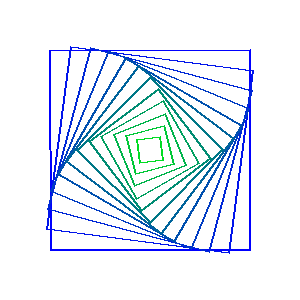

In [ ]:
from PIL import Image, ImageDraw
import math
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image, ImageDraw
import math
bild = Image.new('RGB', (300, 300), 'white')
zeichner = ImageDraw.Draw(bild)
for i in range(12):
    a = 100 - 8 * i
    d = 7.5 * i
    ecken = []
    for k in range(4):
        w = math.radians(d + 45 + 90 * k)
        ecken.append((150 + a * math.sqrt(2) * math.cos(w), 150 + a * math.sqrt(2) * math.sin(w)))
    zeichner.polygon(ecken, outline=(0, 20 * i, 255 - 20 * i), width=2)
bild
```

</details>

## 5. Diagramme von Hand

#### Daten in Pixel umrechnen

Für ein Diagramm muss man Werte in Pixel umrechnen. Bei einem Balkendiagramm mit dem größten Wert `maximum` und der Zeichenhöhe `h` ist ein Balken für den Wert `w`
genau `w / maximum · h` Pixel hoch. Weil `y` nach unten wächst, beginnt der Balken unten bei der Grundlinie und reicht nach **oben**.

In [ ]:
from PIL import Image, ImageDraw, ImageFont

werte = {'Mo': 12, 'Di': 18, 'Mi': 7, 'Do': 15, 'Fr': 20}
bild = Image.new('RGB', (300, 200), 'white')
zeichner = ImageDraw.Draw(bild)
schrift = ImageFont.load_default(size=14)
grundlinie = 170
maximum = max(werte.values())
for i, (tag, wert) in enumerate(werte.items()):
    x = 30 + i * 55
    hoehe = wert / maximum * 140
    zeichner.rectangle((x, grundlinie - hoehe, x + 35, grundlinie), fill='steelblue')
    zeichner.text((x + 17, grundlinie + 15), tag, fill='black', font=schrift, anchor='mm')
zeichner.line((20, grundlinie, 290, grundlinie), fill='black')
bild

#### Aufgabe 5.1

Zeichne ein **waagerechtes** Balkendiagramm für die Lieblingsfächer in der Zelle: für jedes Fach eine Zeile (Abstand 35 Pixel), den Namen links (Größe 14),
den Balken ab x = 100, 15 Pixel pro Stimme, und die Anzahl rechts neben dem Balken.

**Erwartete Ausgabe:**



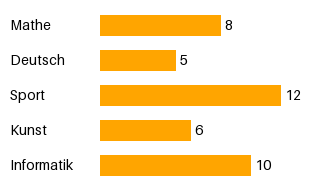

In [ ]:
from PIL import Image, ImageDraw, ImageFont

stimmen = {'Mathe': 8, 'Deutsch': 5, 'Sport': 12, 'Kunst': 6, 'Informatik': 10}
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image, ImageDraw, ImageFont

stimmen = {'Mathe': 8, 'Deutsch': 5, 'Sport': 12, 'Kunst': 6, 'Informatik': 10}
bild = Image.new('RGB', (320, 190), 'white')
zeichner = ImageDraw.Draw(bild)
schrift = ImageFont.load_default(size=14)
for i, (fach, anzahl) in enumerate(stimmen.items()):
    y = 15 + i * 35
    zeichner.text((10, y + 10), fach, fill='black', font=schrift, anchor='lm')
    zeichner.rectangle((100, y, 100 + 15 * anzahl, y + 20), fill='orange')
    zeichner.text((105 + 15 * anzahl, y + 10), str(anzahl), fill='black', font=schrift, anchor='lm')
bild
```

</details>

#### Aufgabe 5.2

Zeichne ein **Kreisdiagramm** für die Stimmen aus der vorigen Aufgabe mit `pieslice()`: Jedes Fach bekommt den Winkel `anzahl / summe · 360`, das erste beginnt bei −90° (oben),
jedes weitere schließt an. Benutze die Farben `['tomato', 'gold', 'yellowgreen', 'skyblue', 'plum']`.

**Erwartete Ausgabe:**



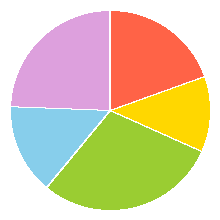

In [ ]:
from PIL import Image, ImageDraw, ImageFont

stimmen = {'Mathe': 8, 'Deutsch': 5, 'Sport': 12, 'Kunst': 6, 'Informatik': 10}
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image, ImageDraw, ImageFont

stimmen = {'Mathe': 8, 'Deutsch': 5, 'Sport': 12, 'Kunst': 6, 'Informatik': 10}
bild = Image.new('RGB', (220, 220), 'white')
zeichner = ImageDraw.Draw(bild)
farben = ['tomato', 'gold', 'yellowgreen', 'skyblue', 'plum']
summe = sum(stimmen.values())
start = -90
for anzahl, farbe in zip(stimmen.values(), farben):
    ende = start + anzahl / summe * 360
    zeichner.pieslice((10, 10, 210, 210), start, ende, fill=farbe, outline='white')
    start = ende
bild
```

</details>

#### Aufgabe 5.3

Zeichne den Graphen von `f(x) = x²` für x von −3 bis 3 in ein 300 × 300-Bild. Die Mitte (150 | 280) ist der Ursprung, 1 Einheit sind 40 Pixel nach rechts und
30 Pixel nach **oben**. Ein Punkt (x | f(x)) liegt also bei Pixel `(150 + 40 x, 280 - 30 f(x))`. Zeichne die Achsen grau und den Graphen als Linie durch 61 Punkte.

**Erwartete Ausgabe:**



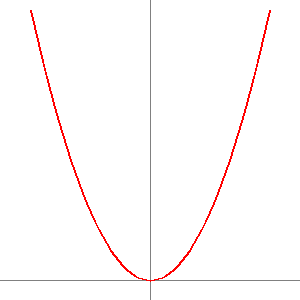

In [ ]:
from PIL import Image, ImageDraw
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image, ImageDraw
bild = Image.new('RGB', (300, 300), 'white')
zeichner = ImageDraw.Draw(bild)
zeichner.line((0, 280, 299, 280), fill='gray')
zeichner.line((150, 0, 150, 299), fill='gray')
punkte = []
for i in range(61):
    x = -3 + i * 0.1
    punkte.append((150 + 40 * x, 280 - 30 * x ** 2))
zeichner.line(punkte, fill='red', width=2)
bild
```

</details>

#### Aufgabe 5.4

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
werte = [4, 10, 6]
maximum = max(werte)
for w in werte:
    print(170 - w / maximum * 150)

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

**Ausgabe:**

```
110.0
20.0
80.0
```

Die Balken sind `w / 10 · 150` hoch, also 60, 150 und 90 Pixel. Von der Grundlinie 170 aus nach oben ergeben sich die oberen Kanten
`110.0`, `20.0` und `80.0`.

</details>

## 6. Gemischte Übungen

#### Aufgabe 6.1

Zeichne eine **Uhr**, die 10:10 Uhr anzeigt: Zifferblatt (Kreis um (150 | 150), Radius 130, weiß mit schwarzem Rand), 12 Striche für die Stunden (von Radius 115 bis 128),
die Zahlen 1 bis 12 (Größe 18) auf Radius 100 und zwei Zeiger. Der Winkel einer Stunde `h` ist `h · 30 - 90` Grad, der einer Minute `m` ist `m · 6 - 90`.
Der Stundenzeiger steht bei 10 Uhr plus 10/60 Stunde (Länge 60, Breite 6), der Minutenzeiger bei 10 Minuten (Länge 95, Breite 4).

**Erwartete Ausgabe:**



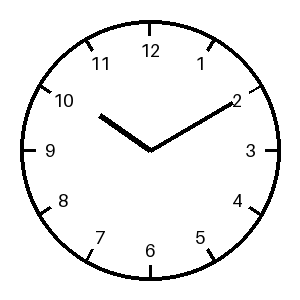

In [ ]:
from PIL import Image, ImageDraw, ImageFont
import math
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image, ImageDraw, ImageFont
import math

def punkt(winkel, radius):
    w = math.radians(winkel)
    return (150 + radius * math.cos(w), 150 + radius * math.sin(w))

bild = Image.new('RGB', (300, 300), 'white')
zeichner = ImageDraw.Draw(bild)
schrift = ImageFont.load_default(size=18)
zeichner.circle((150, 150), 130, fill='white', outline='black', width=4)
for h in range(1, 13):
    zeichner.line(punkt(h * 30 - 90, 115) + punkt(h * 30 - 90, 128), fill='black', width=3)
    zeichner.text(punkt(h * 30 - 90, 100), str(h), fill='black', font=schrift, anchor='mm')
zeichner.line((150, 150) + punkt((10 + 10 / 60) * 30 - 90, 60), fill='black', width=6)
zeichner.line((150, 150) + punkt(10 * 6 - 90, 95), fill='black', width=4)
bild
```

</details>

#### Aufgabe 6.2

Zeichne ein **Mandala**: Wiederhole für `i` von 0 bis 11 (alle 30°) eine Ellipse, die um den Mittelpunkt (150 | 150) gedreht ist. Weil `ellipse()` nicht drehen kann,
nimm stattdessen jeweils einen Kreis mit Radius 50, dessen Mittelpunkt im Abstand 60 unter dem Winkel `30 · i` liegt, nur als Umriss (`outline`, Breite 2).
Dazu kommen 12 kleine gefüllte Kreise (Radius 8) im Abstand 125.

**Erwartete Ausgabe:**



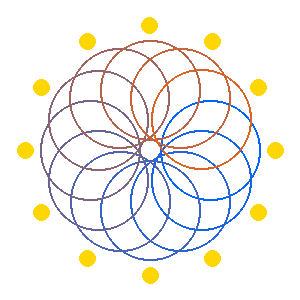

In [ ]:
from PIL import Image, ImageDraw
import math
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image, ImageDraw
import math
bild = Image.new('RGB', (300, 300), 'white')
zeichner = ImageDraw.Draw(bild)
for i in range(12):
    w = math.radians(30 * i)
    zeichner.circle((150 + 60 * math.cos(w), 150 + 60 * math.sin(w)), 50, outline=(20 * i, 100, 255 - 20 * i), width=2)
    zeichner.circle((150 + 125 * math.cos(w), 150 + 125 * math.sin(w)), 8, fill='gold')
bild
```

</details>

#### Aufgabe 6.3

Zähle, wie viele Pixel nach dem Zeichnen eines roten Kreises (Mittelpunkt (50 | 50), Radius 40) in einem weißen 100 × 100-Bild rot sind (`bild.getcolors()` liefert eine
Liste von Paaren (Anzahl, Farbe)). Vergleiche mit `π · 40²` (gerundet).

**Erwartete Ausgabe:**

```
(255, 255, 255) 4855
(255, 0, 0) 5145
5027
```

In [ ]:
from PIL import Image, ImageDraw
import math
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image, ImageDraw
import math
bild = Image.new('RGB', (100, 100), 'white')
zeichner = ImageDraw.Draw(bild)
zeichner.circle((50, 50), 40, fill=(255, 0, 0))
for anzahl, farbe in bild.getcolors():
    print(farbe, anzahl)
print(round(math.pi * 40 ** 2))
```

</details>

#### Aufgabe 6.4

Zeichne ein **Spielfeld für Vier gewinnt**: blaues Brett 7 Spalten × 6 Zeilen mit Feldern von 50 × 50 Pixeln, in jedem Feld ein weißes Loch (Kreis, Radius 20).
Die Liste `zuege` enthält die Spalten, in die abwechselnd Rot und Gelb einen Stein geworfen haben; zeichne die Steine in die richtigen Löcher (sie fallen nach unten).

**Erwartete Ausgabe:**



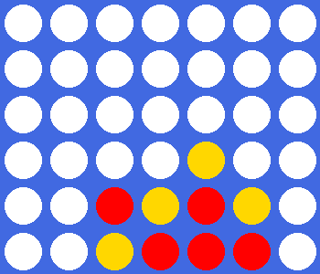

In [ ]:
from PIL import Image, ImageDraw

zuege = [3, 3, 4, 2, 4, 4, 5, 5, 2]
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image, ImageDraw

zuege = [3, 3, 4, 2, 4, 4, 5, 5, 2]
bild = Image.new('RGB', (350, 300), 'royalblue')
zeichner = ImageDraw.Draw(bild)
for spalte in range(7):
    for zeile in range(6):
        zeichner.circle((spalte * 50 + 25, zeile * 50 + 25), 20, fill='white')
hoehe = [0] * 7
for nr, spalte in enumerate(zuege):
    zeile = 5 - hoehe[spalte]
    hoehe[spalte] += 1
    if nr % 2 == 0:
        farbe = 'red'
    else:
        farbe = 'gold'
    zeichner.circle((spalte * 50 + 25, zeile * 50 + 25), 20, fill=farbe)
bild
```

</details>

#### Aufgabe 6.5

Zeichne ein eigenes Bild mit `ImageDraw`: eine Landschaft, ein Fahrzeug, ein Logo oder eine Flagge mit Schleifen und Funktionen.

In [ ]:
# your code

<details>
<summary>Beispiellösung anzeigen (erst selbst probieren!)</summary>

```python
from PIL import Image, ImageDraw

bild = Image.new('RGB', (400, 250), 'skyblue')
zeichner = ImageDraw.Draw(bild)
zeichner.rectangle((0, 180, 399, 249), fill='forestgreen')
zeichner.circle((340, 50), 30, fill='gold')
zeichner.polygon([(0, 180), (120, 60), (240, 180)], fill='gray')
zeichner.polygon([(150, 180), (260, 80), (370, 180)], fill='dimgray')
zeichner.polygon([(100, 80), (120, 60), (140, 80)], fill='white')
bild
```

</details>